# Baseline model: application table only

A first LightGBM on `application_train` to set the benchmark that later feature work must beat, and a SHAP look at what drives it.

## 1. Load and clean
We start from the raw application table and apply the single cleaning rule found in the EDA: the placeholder `365243` in `DAYS_EMPLOYED` becomes NaN, with a flag so the information is kept.

In [1]:
# Load the application table and apply the one cleaning rule from the EDA (placeholder to NaN plus a flag)
import numpy as np
import pandas as pd
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

df = pd.read_csv("../data/raw/HC_application_train.csv")

# Same cleaning as in 01_eda: keep "no job" as a flag, turn the fake value into NaN
df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)

/var/folders/42/t3x7l9v110s8dwq65my59j540000gn/T/ipykernel_83916/2996275101.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)


**Insight:** the data loads without error. The PerformanceWarning only says the table has many columns that were added one by one; it does not affect the result.

## 2. Train the baseline
We split off 20% of applicants (stratified, so both parts keep about 8% positives), train LightGBM on the rest and score ROC-AUC on the held-out part. Every later improvement has to beat this number.

In [2]:
# Baseline: LightGBM with default-style settings on the application table only, one stratified 80/20 split
y = df["TARGET"]
X = df.drop(columns=["TARGET", "SK_ID_CURR"])   # the ID carries no signal
for c in X.select_dtypes(include=["object", "string"]):   # LightGBM needs category dtype, not text
    X[c] = X[c].astype("category")

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
model.fit(X_tr, y_tr)
print("Validation AUC:", roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]))

Validation AUC: 0.7596430451983794


**Insight:** the baseline validation AUC is 0.7596 from a single split, so it carries no error bars (the usual fold-to-fold spread in this project is about 0.003 to 0.004). It is close to the 0.7581 cross-validated baseline reported in the README.

## SHAP feature importance

The bar plot ranks features by average impact on the prediction; the beeswarm adds the direction (red = high feature value). Together they show what the baseline relies on.

/Users/dhanyarajendran/Desktop/NeueFische/myproject/Home-Credit-Default-Risk/.venv/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


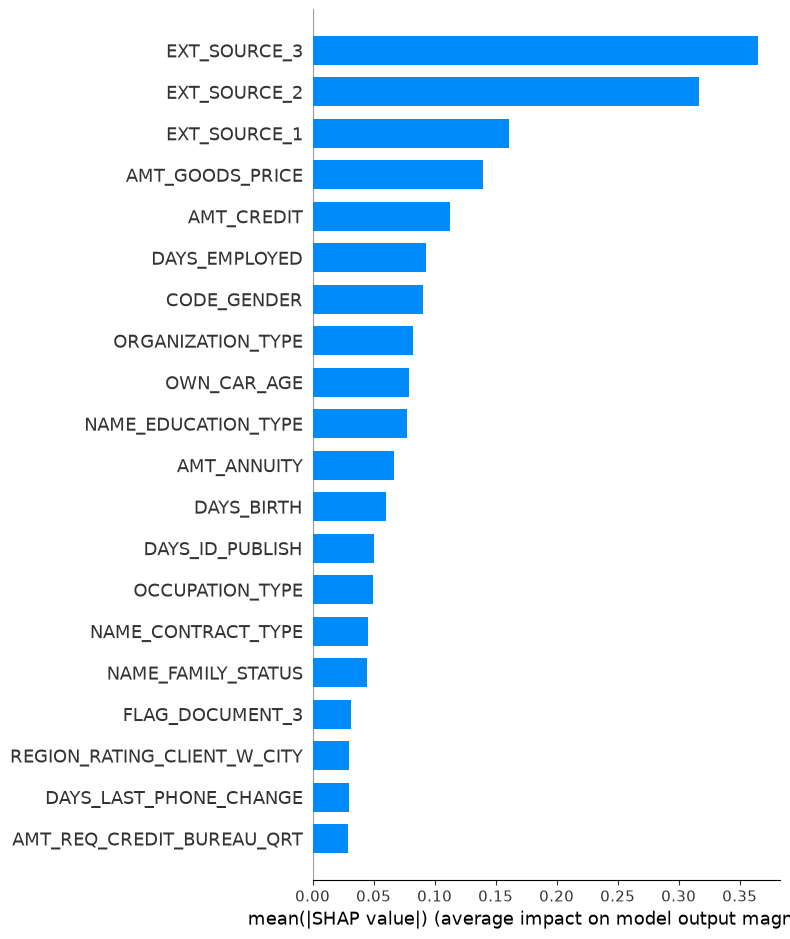

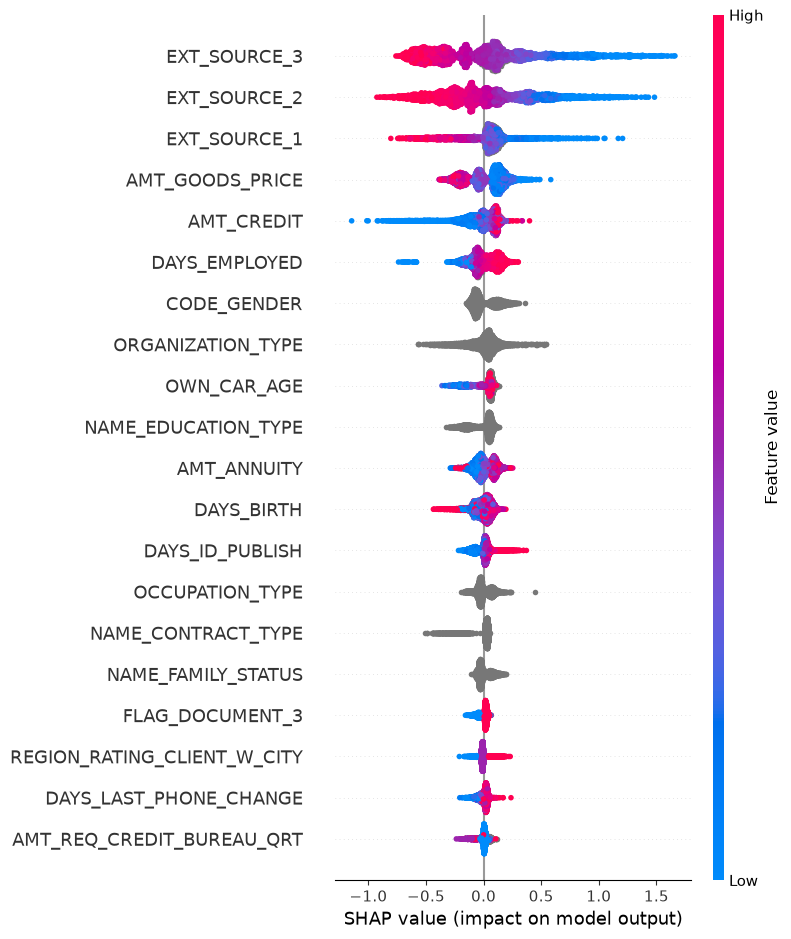

In [3]:
# SHAP on 5,000 validation applicants: bar = overall importance, beeswarm = direction of effect
X_s = X_val.sample(5000, random_state=42)
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_s)
sv = sv[1] if isinstance(sv, list) else sv   # older SHAP returns one array per class

shap.summary_plot(sv, X_s, plot_type="bar", max_display=20)
shap.summary_plot(sv, X_s, max_display=20)

**Insight:** the three external scores are the strongest features: `EXT_SOURCE_3` (about 0.36), `EXT_SOURCE_2` (about 0.32) and `EXT_SOURCE_1` (about 0.16), followed by loan size (`AMT_GOODS_PRICE`, `AMT_CREDIT`) and `DAYS_EMPLOYED`. `CODE_GENDER`, a sensitive attribute, is also in the top ten, which is noted in the README. The bar values are read off the plot, so they are approximate.